Example 4: Spectral Estimation with Non-Additive (Interacting) Spectra

A port of the standalone ``joint_estimation.py`` demo onto the ReactionModel
API. It makes one point, in three fits:

    Fitting an additive Beer-Lambert model to interacting spectra does not
    merely leave a larger residual. The flexible ``C @ S.T`` product ABSORBS the
    interaction into distorted spectra, and the kinetic parameters come out
    BIASED.

Chemistry: A -> B -> C, with A and B overlapping in time so a transient A.B
adduct forms. The adduct has a vibrational mode neither monomer has, and its
intensity goes as ``c_A * c_B`` -- a virial (quadratic-in-concentration) term
that breaks bilinearity:

    D(t, nu) = sum_k c_k(t) s_k(nu)  +  c_A(t) c_B(t) Gamma_AB(nu)

The repair is ``ReactionModel.interaction``: an extra column of C whose value is
an arbitrary algebraic expression of the states, carrying its own signed
spectrum. Declaring ``r.interaction('AB', A * B)`` recovers the rate constants
AND hands back Gamma_AB as an extra column of S.

An interaction is NOT a differential state. It is tempting to give ``AB`` an ODE
via the product rule, ``d(c_A c_B)/dt = c_A' c_B + c_A c_B'``, and that does
integrate correctly -- but it adds a spurious quadratic differential constraint
to the collocation NLP. Measured on this problem, the ODE form converged to
k1 = 0.756 (16% error) from any starting point, while the algebraic column gets
k1 = 0.904 (0.4%). The constraint, not the physics, was the difference.

Because the augmented model is strictly more flexible, its interaction spectra
can trade against the rate constants. ``set_spectral_regularization`` applies a
ridge to keep the fit identified. Model selection (rank and structured-residual
diagnostics) should precede model augmentation.

NOTE: all data here is SYNTHETIC, generated by the model below.

In [1]:
%matplotlib inline
import sys
sys.path.insert(0, '..')
import os

## Setup: helper functions and synthetic-data generators

These are lifted verbatim from the example script (`kipetax/examples/Ex_4_spectral_interactions.py`).

In [2]:
import numpy as np
import pandas as pd

from kipetax import ReactionModel

K1_TRUE, K2_TRUE = 0.9, 0.5
A0 = 1.0
G_STRENGTH = 1.6            # adduct band strength

# The main story below uses the SIMULTANEOUS collocation solver (the default),
# on a deliberately coarse 24-point spectral axis. That solver makes the
# pure-component spectra S (n_comp x n_lam) NLP decision variables, so its cost
# grows roughly QUADRATICALLY in n_lam: three fits at 24 wavelengths take ~20 s,
# while a single fit at 100 wavelengths does not finish in 175 s. The coarse axis
# keeps the pedagogy fast, and the S >= 0 constraint it enforces is what makes
# the naive-vs-aware bias show up cleanly in the rate constants.
#
# The fast alternative is variable projection (method='varpro'): S is eliminated
# analytically (S* = C^+ D) so the optimizer sees only k1, k2 and the cost is
# INDEPENDENT of the wavelength count. varpro_demo() below runs the same
# interaction-aware fit at the full 400-wavelength resolution in ~1 s. (Because
# varpro uses free spectra, it identifies only the SET {k1, k2}; a species
# non-negativity penalty resolves the A->B vs B->C assignment.)
NU = np.linspace(300.0, 1700.0, 24)     # Raman shift, cm^-1
T = np.linspace(0.0, 10.0, 25)          # time

def lorentzian(nu, nu0, gamma, amp):
    return amp * gamma ** 2 / ((nu - nu0) ** 2 + gamma ** 2)

def spec_A(nu):
    return lorentzian(nu, 520.0, 15.0, 1.0) + lorentzian(nu, 1000.0, 20.0, 0.6)

def spec_B(nu):
    return lorentzian(nu, 700.0, 18.0, 0.8) + lorentzian(nu, 1350.0, 25.0, 0.7)

def spec_C(nu):
    return lorentzian(nu, 900.0, 20.0, 0.9) + lorentzian(nu, 1600.0, 22.0, 1.0)

def spec_complex_AB(nu):
    """Mode unique to the A.B adduct: exists only when both are present."""
    return lorentzian(nu, 1150.0, 20.0, 0.7)

def true_concentrations():
    """Analytic A -> B -> C profiles (data generation only)."""
    k1, k2 = K1_TRUE, K2_TRUE
    cA = A0 * np.exp(-k1 * T)
    cB = A0 * k1 / (k2 - k1) * (np.exp(-k1 * T) - np.exp(-k2 * T))
    cC = A0 - cA - cB
    return cA, cB, cC

def build_data(noise=2e-3, seed=0):
    cA, cB, cC = true_concentrations()
    SA, SB, SC = spec_A(NU), spec_B(NU), spec_C(NU)

    D_add = np.outer(cA, SA) + np.outer(cB, SB) + np.outer(cC, SC)
    D_int = D_add + G_STRENGTH * np.outer(cA * cB, spec_complex_AB(NU))

    rng = np.random.default_rng(seed)
    D_add = D_add + noise * rng.standard_normal(D_add.shape)
    D_int = D_int + noise * rng.standard_normal(D_int.shape)

    to_df = lambda M: pd.DataFrame(M, index=T, columns=NU)
    return to_df(D_add), to_df(D_int)

def build_model(name, interaction_aware, ridge=1e-3):
    """A -> B -> C, optionally augmented with the c_A*c_B interaction column."""
    r = ReactionModel(name)

    k1 = r.parameter('k1', value=0.6, bounds=(0.05, 3.0))
    k2 = r.parameter('k2', value=0.35, bounds=(0.05, 3.0))

    A = r.component('A', value=A0)
    B = r.component('B', value=0.0)
    C = r.component('C', value=0.0)

    r.add_ode('A', -k1 * A)
    r.add_ode('B', k1 * A - k2 * B)
    r.add_ode('C', k2 * B)

    if interaction_aware:
        # The A.B adduct band: an algebraic column of C, intensity ~ c_A c_B.
        # Its fitted spectrum comes back as S['AB'].
        r.interaction('AB', A * B)
        r.set_spectral_regularization(ridge=ridge)

    r.set_discretization(nfe=15, ncp=3)
    return r

def run_fit(label, data, interaction_aware):
    r = build_model(label, interaction_aware)
    r.add_data(name='spectral', data=data, category='spectral')
    r.run_opt(variances={'device': 4e-6})

    ro = r.results_dict['p_estimator']
    k1, k2 = ro.P.get('k1', np.nan), ro.P.get('k2', np.nan)
    e1 = abs(k1 - K1_TRUE) / K1_TRUE * 100
    e2 = abs(k2 - K2_TRUE) / K2_TRUE * 100
    print(f"\n{label}")
    print(f"  k1 = {k1:.4f}  (true {K1_TRUE})   error {e1:5.2f}%")
    print(f"  k2 = {k2:.4f}  (true {K2_TRUE})   error {e2:5.2f}%")
    return ro, max(e1, e2)

def varpro_demo():
    """The same interaction-aware fit by variable projection, at the FULL
    400-wavelength resolution the collocation solver could not afford."""
    import time

    nu = np.linspace(200.0, 1800.0, 400)
    t = np.linspace(0.0, 10.0, 60)
    cA, cB, cC = (np.exp(-K1_TRUE * t),
                  K1_TRUE / (K2_TRUE - K1_TRUE) * (np.exp(-K1_TRUE * t) - np.exp(-K2_TRUE * t)),
                  None)
    cC = 1.0 - cA - cB

    def lor(c, w, a):
        return a * w ** 2 / ((nu - c) ** 2 + w ** 2)
    SA = lor(520, 15, 1.0) + lor(1000, 20, 0.6)
    SB = lor(700, 18, 0.8) + lor(1350, 25, 0.7)
    SC = lor(900, 20, 0.9) + lor(1600, 22, 1.0)
    SAB = lor(1150, 20, 0.7)
    D = (np.outer(cA, SA) + np.outer(cB, SB) + np.outer(cC, SC)
         + G_STRENGTH * np.outer(cA * cB, SAB))
    D = D + 2e-3 * np.random.default_rng(0).standard_normal(D.shape)
    df = pd.DataFrame(D, index=t, columns=nu)

    r = ReactionModel('varpro_400')
    k1 = r.parameter('k1', value=0.3, bounds=(0.05, 3.0))   # swapped start
    k2 = r.parameter('k2', value=1.4, bounds=(0.05, 3.0))
    A = r.component('A', value=1.0)
    B = r.component('B', value=0.0)
    C = r.component('C', value=0.0)
    r.add_ode('A', -k1 * A)
    r.add_ode('B', k1 * A - k2 * B)
    r.add_ode('C', k2 * B)
    r.interaction('AB', A * B)
    r.add_data(name='spectral', data=df, category='spectral')

    t0 = time.time()
    r.run_opt(variances={'device': 4e-6}, method='varpro')
    dt = time.time() - t0
    ro = r.results_dict['p_estimator']

    print("\n" + "=" * 68)
    print(f"Variable projection at {len(nu)} wavelengths (method='varpro')")
    print("=" * 68)
    print(f"  k1 = {ro.P['k1']:.4f} (true {K1_TRUE})   "
          f"k2 = {ro.P['k2']:.4f} (true {K2_TRUE})   in {dt:.1f} s")
    g = ro.S['AB'].values
    gt = G_STRENGTH * SAB
    print(f"  Gamma_AB cosine similarity = {float(g @ gt) / (np.linalg.norm(g) * np.linalg.norm(gt)):.4f}")
    print("  S was projected out, so the cost did not grow with the wavelength "
          "count.")
    return ro

## Run the analysis

In [3]:
D_add, D_int = build_data()

In [4]:
print("=" * 68)
print("1. additive model on ADDITIVE data  -- the estimator is sound")
print("=" * 68)
_, err_sound = run_fit('additive_on_additive', D_add, interaction_aware=False)

1. additive model on ADDITIVE data  -- the estimator is sound


Parameter estimation complete: status=optimal
  k1                   = 0.904099
  k2                   = 0.49696

additive_on_additive
  k1 = 0.9041  (true 0.9)   error  0.46%
  k2 = 0.4970  (true 0.5)   error  0.61%


In [5]:
print("\n" + "=" * 68)
print("2. additive model on INTERACTING data -- biased rate constants")
print("=" * 68)
_, err_biased = run_fit('naive_on_interacting', D_int, interaction_aware=False)


2. additive model on INTERACTING data -- biased rate constants


Parameter estimation complete: status=optimal
  k1                   = 0.969245
  k2                   = 0.508472

naive_on_interacting
  k1 = 0.9692  (true 0.9)   error  7.69%
  k2 = 0.5085  (true 0.5)   error  1.69%


In [6]:
print("\n" + "=" * 68)
print("3. interaction-aware model on INTERACTING data -- bias removed")
print("=" * 68)
ro_aware, err_aware = run_fit('aware_on_interacting', D_int, interaction_aware=True)


3. interaction-aware model on INTERACTING data -- bias removed


Parameter estimation complete: status=optimal
  k1                   = 0.903603
  k2                   = 0.493054

aware_on_interacting
  k1 = 0.9036  (true 0.9)   error  0.40%
  k2 = 0.4931  (true 0.5)   error  1.39%


In [7]:
print("\n" + "=" * 68)
print("Summary (max |error| over k1, k2)")
print("=" * 68)
print(f"  additive model, additive data     : {err_sound:6.2f}%")
print(f"  additive model, interacting data  : {err_biased:6.2f}%   <- bias")
print(f"  aware model,    interacting data  : {err_aware:6.2f}%")


Summary (max |error| over k1, k2)
  additive model, additive data     :   0.61%
  additive model, interacting data  :   7.69%   <- bias
  aware model,    interacting data  :   1.39%


In [8]:
# The adduct spectrum comes back as the AB row of S.
if ro_aware.S is not None and 'AB' in ro_aware.S.columns:
    gamma_fit = ro_aware.S['AB'].values
    gamma_true = G_STRENGTH * spec_complex_AB(NU)
    num = float(gamma_fit @ gamma_true)
    den = float(np.linalg.norm(gamma_fit) * np.linalg.norm(gamma_true))
    print(f"\n  recovered Gamma_AB vs true: cosine similarity = {num / den:.4f}")
    print(f"  peak at {NU[int(np.argmax(gamma_fit))]:.0f} cm^-1 "
          f"(true adduct band: 1150 cm^-1)")


  recovered Gamma_AB vs true: cosine similarity = 0.9989
  peak at 1152 cm^-1 (true adduct band: 1150 cm^-1)


In [9]:
ro_aware

ResultsObject(status='optimal', objective=462.1265939696998, params=[k1=0.903603, k2=0.493054])

## Visualization

Persistent figures: the transient A.B adduct, the recovered interaction band, the rate-constant bias across three fits, and the interaction contribution to D.

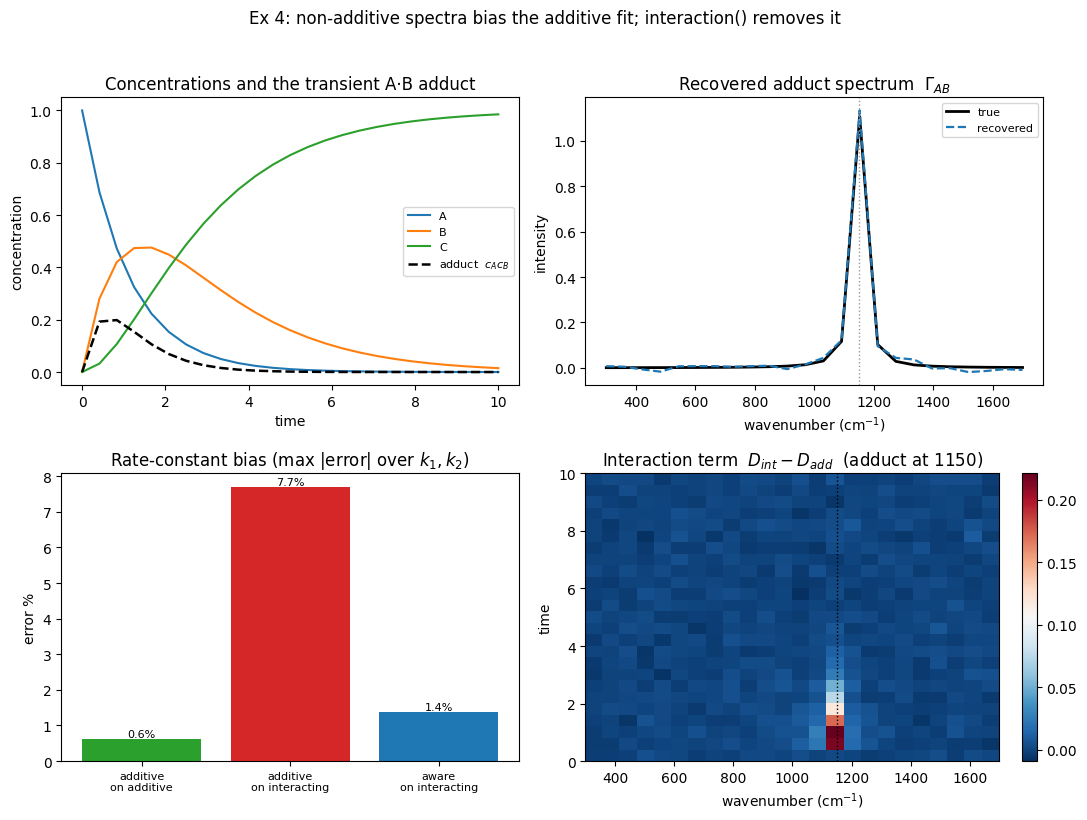

In [10]:
import matplotlib.pyplot as plt

cA, cB, cC = true_concentrations()
gamma_fit = ro_aware.S['AB'].values
gamma_true = G_STRENGTH * spec_complex_AB(NU)

fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# (a) Concentrations and the transient A.B adduct coefficient c_A*c_B.
ax[0, 0].plot(T, cA, label='A')
ax[0, 0].plot(T, cB, label='B')
ax[0, 0].plot(T, cC, label='C')
ax[0, 0].plot(T, cA * cB, 'k--', lw=1.8, label='adduct  $c_A c_B$')
ax[0, 0].set(title='Concentrations and the transient A·B adduct',
             xlabel='time', ylabel='concentration')
ax[0, 0].legend(fontsize=8)

# (b) Recovered adduct band Gamma_AB (an extra, signed column of S).
ax[0, 1].plot(NU, gamma_true, 'k-', lw=2, label='true')
ax[0, 1].plot(NU, gamma_fit, 'C0--', lw=1.6, label='recovered')
ax[0, 1].axvline(1150, color='0.6', ls=':', lw=1)
ax[0, 1].set(title=r'Recovered adduct spectrum  $\Gamma_{AB}$',
             xlabel='wavenumber (cm$^{-1}$)', ylabel='intensity')
ax[0, 1].legend(fontsize=8)

# (c) The bias story: max|error| over k1,k2 for the three fits.
labels = ['additive\non additive', 'additive\non interacting',
          'aware\non interacting']
errs = [err_sound, err_biased, err_aware]
ax[1, 0].bar(range(3), errs, color=['C2', 'C3', 'C0'])
for i, e in enumerate(errs):
    ax[1, 0].annotate(f'{e:.1f}%', (i, e), ha='center', va='bottom', fontsize=8)
ax[1, 0].set_xticks(range(3))
ax[1, 0].set_xticklabels(labels, fontsize=8)
ax[1, 0].set(title=r'Rate-constant bias (max |error| over $k_1,k_2$)',
             ylabel='error %')

# (d) The interaction term the additive model must absorb: D_int - D_add.
diff = (D_int - D_add).values
im = ax[1, 1].imshow(diff, aspect='auto', origin='lower', cmap='RdBu_r',
                     extent=[NU[0], NU[-1], T[0], T[-1]])
ax[1, 1].axvline(1150, color='k', ls=':', lw=1)
fig.colorbar(im, ax=ax[1, 1], fraction=0.046)
ax[1, 1].set(title='Interaction term  $D_{int}-D_{add}$  (adduct at 1150)',
             xlabel='wavenumber (cm$^{-1}$)', ylabel='time')

fig.suptitle('Ex 4: non-additive spectra bias the additive fit; '
             'interaction() removes it', y=1.02)
fig.tight_layout()